# SECOM — Data Understanding & Data Preparation (Steps 1–2)

**CRISP-DM phases covered:** Business Understanding → Data Understanding → Data Preparation
(rough feature reduction, outlier treatment).

| Section | Content |
|---|---|
| 1 | Background of the dataset; what rows and columns mean |
| 2 | Descriptive statistics; target coding; class balance |
| 3 | Missing-value audit: are *all* missing values flagged as missing? |
| 4 | Stratified 80/20 train/test split; the test set is sealed and put aside |
| 5 | Rough feature reduction **(training set only)**: constant features, features with many N/As |
| 6 | Correlation heatmap (visualise only; nothing removed) |
| 7 | Outliers with the 3σ rule: options, decision, implementation |
| 8 | Summary of the preparation funnel and saved state |

Every preparation step ends with a **Step Impact Protocol (SIP) table**: the options, their
pros and cons, the decision made, and its consequence. The numbers in the SIP tables are
computed in the notebook, not typed by hand. Each decision is also logged in
`docs/scientific_diary.md`.

> **Ground rule:** after Section 4 the test set is **never loaded again** in this notebook.
> Every statistic, threshold and boundary from Section 5 onward comes from the training set.

## 1. Background of the dataset

**Source.** SECOM (*SEmiCOnductor Manufacturing*), UCI Machine Learning Repository, donated
in 2008 by Michael McCann and Adrian Johnston.

**Process.** Semiconductor wafers go through hundreds of production steps monitored by
hundreds of sensors, while pass/fail testing occurs at the line. Catching defects late or
relying on noisy, high-dimensional signals lowers yield and raises cost per good unit.
Guided by CRISP-DM and prior SECOM fault-detection literature (feature selection and
rare-case handling), the goal is to isolate key signals and predict defects early.

**What the files mean**

| File | Content |
|---|---|
| `secom.data` | 1,567 rows × 590 columns of real-valued measurements, space-separated; missing values written as `NaN` |
| `secom_labels.data` | 1,567 rows: the pass/fail label (−1 / 1) and the date-time stamp of the test |
| `secom.names` | Dataset description |

- **One row** = one production entity (a wafer or lot) that went through the line and
  was tested in house. Row *i* of the data file belongs to row *i* of the label file.
- **One column** = one sensor or process-measurement signal. Columns are **anonymised**:
  there are no names and no units, only positions, which we call `feature_000` …
  `feature_589`. Every decision has to be driven by the data.
- **Target** = the yield outcome of in-house line testing (pass or fail), with a timestamp.

## 2. Descriptive statistics

### 2.1 Coding of defective and good wafers

In [36]:
from __future__ import annotations

from datetime import datetime, timezone
import hashlib
import json
from pathlib import Path
from typing import Iterable

import numpy as np
import pandas as pd


def zero_variance_features(df: pd.DataFrame) -> tuple[pd.Series, list[str]]:
    """Compute NaN-aware column variance and return (variance_series, exact_zero_cols)."""
    variance = df.var(axis=0, skipna=True, ddof=1)
    zero_cols = variance[variance == 0.0].index.tolist()
    return variance, zero_cols


def missing_percentage(df: pd.DataFrame) -> pd.Series:
    """Return percentage (0-100) of missing values per column."""
    return df.isna().mean(axis=0) * 100.0


def missing_threshold_pareto(missing_pct: pd.Series) -> pd.DataFrame:
    """For thresholds 0..100 (remove if missing_pct > threshold), count removed columns."""
    thresholds = np.arange(0, 101, 1)
    arr = missing_pct.to_numpy(dtype=float)
    removed = [int(np.sum(arr > t)) for t in thresholds]
    return pd.DataFrame({"threshold_pct": thresholds, "columns_removed": removed})


def three_sigma_bounds(df: pd.DataFrame, k: float = 3.0) -> pd.DataFrame:
    """Compute [lower, upper] = mean +/- k * std per column using NaN-aware stats."""
    means = df.mean(axis=0, skipna=True)
    stds = df.std(axis=0, skipna=True, ddof=1)
    return pd.DataFrame({
        "mean": means,
        "std": stds,
        "lower": means - k * stds,
        "upper": means + k * stds,
    })


def flag_outliers(df: pd.DataFrame, bounds: pd.DataFrame) -> pd.DataFrame:
    """Boolean mask of values strictly outside [lower, upper]; NaNs remain False."""
    lower = bounds["lower"]
    upper = bounds["upper"]
    below = df.lt(lower, axis=1).fillna(False)
    above = df.gt(upper, axis=1).fillna(False)
    return below | above


def cap_outliers(df: pd.DataFrame, bounds: pd.DataFrame) -> pd.DataFrame:
    """Clip values to [lower, upper] while preserving existing NaNs."""
    return df.clip(lower=bounds["lower"], upper=bounds["upper"], axis=1)


def remove_outliers(df: pd.DataFrame, bounds: pd.DataFrame) -> pd.DataFrame:
    """Set values outside [lower, upper] to NaN while preserving existing NaNs."""
    mask = flag_outliers(df, bounds)
    return df.mask(mask, np.nan)


def sip_table(rows: Iterable[tuple[str, str, str, str]]) -> pd.DataFrame:
    """Build a Step Impact Protocol (SIP) table."""
    return pd.DataFrame(
        list(rows),
        columns=["Option", "Pros & Cons", "Decision", "Consequence"],
    )


def _sha256_file(path: Path) -> str:
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(65536), b""):
            h.update(chunk)
    return h.hexdigest()


def save_split(
    X: pd.DataFrame,
    y: pd.Series,
    out_csv: Path,
    seal: bool = False,
) -> str:
    """Save features + target to CSV; optionally write a .sha256 fingerprint."""
    out_csv.parent.mkdir(parents=True, exist_ok=True)
    combined = X.copy()
    combined["defective"] = y.loc[X.index].astype(int)
    combined.to_csv(out_csv, index=True)
    digest = _sha256_file(out_csv)
    if seal:
        sha_path = out_csv.with_suffix(out_csv.suffix + ".sha256")
        sha_path.write_text(f"{digest}  {out_csv.name}\n", encoding="utf-8")
    return digest


def verify_sealed(csv_path: Path) -> bool:
    """Verify csv_path against its sidecar .sha256 file."""
    sha_path = csv_path.with_suffix(csv_path.suffix + ".sha256")
    if not csv_path.exists() or not sha_path.exists():
        return False
    expected = sha_path.read_text(encoding="utf-8").strip().split()[0]
    return _sha256_file(csv_path) == expected


def save_state(state: dict, out_json: Path) -> None:
    """Save preparation metadata and funnel counts as JSON."""
    out_json.parent.mkdir(parents=True, exist_ok=True)
    out_json.write_text(json.dumps(state, indent=2), encoding="utf-8")


def log_diary_entry(
    diary_path: Path,
    entry_id: str,
    step_title: str,
    decision: str,
    rationale: str,
    consequence: str,
) -> None:
    """Append a structured decision entry to docs/scientific_diary.md without duplicates."""
    diary_path.parent.mkdir(parents=True, exist_ok=True)
    header = "# Scientific Diary — SECOM Data Understanding & Preparation\n\n"
    if not diary_path.exists():
        diary_path.write_text(header, encoding="utf-8")
    existing = diary_path.read_text(encoding="utf-8")
    marker = f"### {entry_id}:"
    if marker in existing:
        return
    block = (
        f"### {entry_id}: {step_title}\n"
        f"- **Timestamp (UTC):** {datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M')}\n"
        f"- **Decision:** {decision}\n"
        f"- **Rationale:** {rationale}\n"
        f"- **Consequence:** {consequence}\n\n"
    )
    with diary_path.open("a", encoding="utf-8") as f:
        f.write(block)


In [37]:
from __future__ import annotations

from pathlib import Path
import pandas as pd


def resolve_data_dir(base_dir: Path) -> Path:
    """Find the folder containing secom.data and secom_labels.data."""
    candidates = [
        base_dir,
        base_dir / "raw",
        Path(r"C:\Users\LindaAlyAbdellateefA\Downloads\SECOM\secom\data\raw"),
    ]
    for cand in candidates:
        if (cand / "secom.data").exists() and (cand / "secom_labels.data").exists():
            return cand
    raise FileNotFoundError(
        f"Could not locate secom.data and secom_labels.data under {base_dir}"
    )


def load_secom(data_dir: Path) -> tuple[pd.DataFrame, pd.Series]:
    """Load 1,567 x 590 sensor matrix and binary target (0 = pass/-1, 1 = fail/1)."""
    X = pd.read_csv(
        data_dir / "secom.data",
        sep=r"\s+",
        header=None,
        na_values=["NaN", "nan", "NA", ""],
    )
    X.columns = [f"feature_{i:03d}" for i in range(X.shape[1])]
    labels = load_labels(data_dir)
    y = labels["label"].map({-1: 0, 1: 1}).astype(int)
    y.index = X.index
    return X, y


def load_labels(data_dir: Path) -> pd.DataFrame:
    """Load raw pass/fail label (-1/1) and timestamp from secom_labels.data."""
    df = pd.read_csv(
        data_dir / "secom_labels.data",
        sep="\t",
        header=0,
        names=["label", "date", "time"],
    )
    df["label"] = df["label"].astype(int)
    df["timestamp"] = pd.to_datetime(
        df["date"] + " " + df["time"],
        format="%d/%m/%Y %H:%M:%S",
        errors="coerce",
    )
    return df[["label", "timestamp"]]


In [38]:
from pathlib import Path
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore", category=RuntimeWarning)

ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
SRC_DIR = ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

DATA_DIR = resolve_data_dir(ROOT / "data" / "raw")
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "reports" / "figures"
DIARY_PATH = ROOT / "docs" / "scientific_diary.md"
FIGURES.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
TEST_SIZE = 0.20

# Chart style: two fixed series colours (blue = pass / kept, orange = fail / removed),
# recessive grid, no top/right spines.
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#7b7a75"
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#ecebe7",
    "axes.axisbelow": True,
    "axes.edgecolor": MUTED,
    "axes.labelcolor": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "font.size": 10,
})
pd.set_option("display.max_columns", 30, "display.width", 140)


def savefig(fig, name: str) -> None:
    fig.tight_layout()
    fig.savefig(FIGURES / name, bbox_inches="tight")
    plt.show()


print("ROOT:", ROOT)
print("DATA_DIR:", DATA_DIR)


ROOT: C:\Users\LindaAlyAbdellateefA\Downloads\SECOM\secom
DATA_DIR: C:\Users\LindaAlyAbdellateefA\Downloads\SECOM\secom\data\raw


In [39]:
names_path = DATA_DIR / "secom.names"
if names_path.exists():
    for line in names_path.read_text(encoding="utf-8", errors="replace").splitlines():
        if any(key in line for key in (
            "Number of Instances", "Number of Attributes",
            "Attribute Characteristics", "Missing Values",
            "Date Donated", "Associated Tasks",
        )):
            print(line.strip())

X, y = load_secom(DATA_DIR)          # features (NaN = missing) and target (0 = pass, 1 = fail)
labels = load_labels(DATA_DIR)       # raw label (-1/1) and timestamp
print(f"\nfeatures: {X.shape[0]:,} rows x {X.shape[1]} columns   labels: {labels.shape[0]:,} rows")
print("The .names file counts 591 attributes = 590 measurements + 1 label.")
display(X.iloc[:5, :10])


Number of Instances: 1567
Attribute Characteristics: Real
Number of Attributes: 591
Date Donated: 2008-11-19
Associated Tasks: Classification, Causal-Discovery
Missing Values? Yes

features: 1,567 rows x 590 columns   labels: 1,567 rows
The .names file counts 591 attributes = 590 measurements + 1 label.


,feature_000,feature_001,feature_002,feature_003,feature_004,feature_005,feature_006,feature_007,feature_008,feature_009
0,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242,1.5005,0.0162
1,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247,1.4966,-0.0005
2,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241,1.4436,0.0041
3,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217,1.4882,-0.0124
4,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235,1.5031,-0.0031


,raw code (secom_labels.data),meaning,coded as `defective`,count,percentage
0,-1,pass: good wafer,0,1463,93.36
1,1,fail: defective wafer,1,104,6.64


Defective wafers: 104 of 1,567 = 6.64 %
Imbalance ratio good : defective = 14.1 : 1
Accuracy of a model that always predicts 'pass': 93.36 %


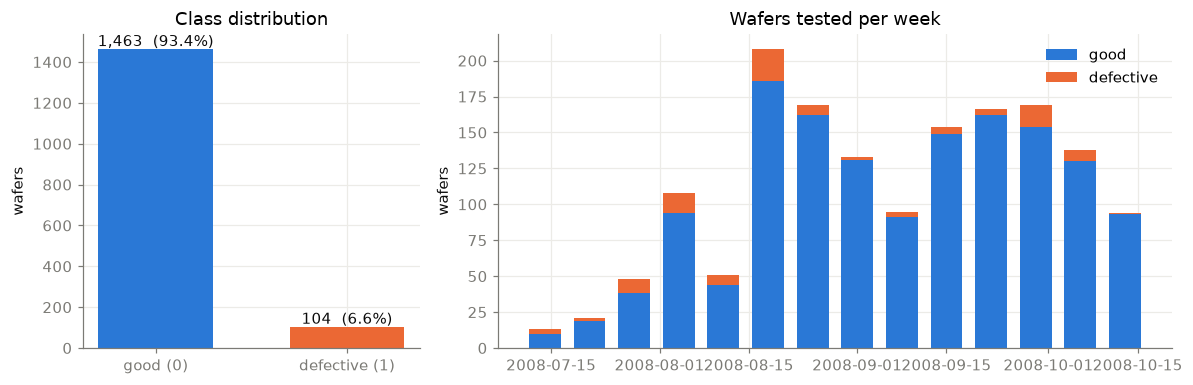

Production window: 2008-07-19 to 2008-10-17


In [40]:
coding = pd.DataFrame({
    "raw code (secom_labels.data)": [-1, 1],
    "meaning": ["pass: good wafer", "fail: defective wafer"],
    "coded as `defective`": [0, 1],
})
counts = labels["label"].value_counts()
coding["count"] = coding["raw code (secom_labels.data)"].map(counts)
coding["percentage"] = (coding["count"] / coding["count"].sum() * 100).round(2)
display(coding)

defect_pct = y.mean() * 100
ratio = (1 - y.mean()) / y.mean()
print(f"Defective wafers: {int(y.sum())} of {len(y):,} = {defect_pct:.2f} %")
print(f"Imbalance ratio good : defective = {ratio:.1f} : 1")
print(f"Accuracy of a model that always predicts 'pass': {100 - defect_pct:.2f} %")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 2]})
bars = axes[0].bar(
    ["good (0)", "defective (1)"],
    [int((y == 0).sum()), int(y.sum())],
    color=[BLUE, ORANGE],
    width=0.6,
)
for bar, value in zip(bars, [(y == 0).mean(), y.mean()]):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 15,
        f"{bar.get_height():,.0f}  ({value:.1%})",
        ha="center",
        color=INK,
    )
axes[0].set(title="Class distribution", ylabel="wafers")

weekly = (
    labels.assign(
        week=labels["timestamp"].dt.to_period("W").dt.start_time,
        fail=labels["label"].eq(1),
    )
    .groupby("week")["fail"]
    .agg(["size", "sum"])
)
axes[1].bar(weekly.index, weekly["size"] - weekly["sum"], width=5, color=BLUE, label="good")
axes[1].bar(
    weekly.index,
    weekly["sum"],
    width=5,
    bottom=weekly["size"] - weekly["sum"],
    color=ORANGE,
    label="defective",
)
axes[1].set(title="Wafers tested per week", ylabel="wafers")
axes[1].legend(frameon=False)
savefig(fig, "01_class_distribution.png")
print(f"Production window: {labels['timestamp'].min():%Y-%m-%d} to {labels['timestamp'].max():%Y-%m-%d}")


### 2.2 Is the dataset balanced? Why?

**No, it is strongly imbalanced.** About 93.4% of wafers are good and 6.6% defective,
roughly **14 good wafers for every defective one**.

**Why.** A semiconductor line runs under tight statistical process control, so failures are
rare by design. Missing a defect also carries higher downstream cost than a false alarm.

**Consequences for the project**
- **Accuracy is misleading.** A model that always says "pass" scores ~93.4% accuracy while
  catching zero defects.
- **Splits must preserve the minority share** via stratified sampling (Section 4).
- **Balancing** (such as minority over-sampling / boosting) is applied to the training set
  only in later modeling steps.

### 2.3 Descriptive statistics of the measurements

In [41]:
desc = X.describe().T
desc["missing_pct"] = X.isna().mean() * 100
desc["range"] = desc["max"] - desc["min"]
display(desc.head(10).round(4))

overview = pd.Series({
    "rows": X.shape[0],
    "columns": X.shape[1],
    "missing cells": int(X.isna().sum().sum()),
    "missing cells %": round(X.isna().mean().mean() * 100, 2),
    "columns without missing values": int(X.notna().all().sum()),
    "rows without missing values": int(X.notna().all(axis=1).sum()),
    "columns with zero variance (full data)": int(X.var().eq(0).sum()),
    "smallest column std (non-zero)": float(desc.loc[desc["std"] > 0, "std"].min()),
    "largest column std": float(desc["std"].max()),
    "columns with |skew| > 2": int(X.skew().abs().gt(2).sum()),
}, name="value", dtype=object)
display(overview.to_frame())


,count,mean,std,min,25%,50%,75%,max,missing_pct,range
feature_000,1561.0,3014.4529,73.6218,2743.2400,2966.2600,3011.4900,3056.6500,3356.3500,0.3829,613.1100
feature_001,1560.0,2495.8502,80.4077,2158.7500,2452.2475,2499.4050,2538.8225,2846.4400,0.4467,687.6900
feature_002,1553.0,2200.5473,29.5132,2060.6600,2181.0444,2201.0667,2218.0555,2315.2667,0.8934,254.6067
feature_003,1553.0,1396.3766,441.6916,0.0000,1081.8758,1285.2144,1591.2235,3715.0417,0.8934,3715.0417
feature_004,1553.0,4.1970,56.3555,0.6815,1.0177,1.3168,1.5257,1114.5366,0.8934,1113.8551
feature_005,1553.0,100.0000,0.0000,100.0000,100.0000,100.0000,100.0000,100.0000,0.8934,0.0000
feature_006,1553.0,101.1129,6.2372,82.1311,97.9200,101.5122,104.5867,129.2522,0.8934,47.1211
feature_007,1558.0,0.1218,0.0090,0.0000,0.1211,0.1224,0.1238,0.1286,0.5743,0.1286
feature_008,1565.0,1.4629,0.0739,1.1910,1.4112,1.4616,1.5169,1.6564,0.1276,0.4654
feature_009,1565.0,-0.0008,0.0151,-0.0534,-0.0108,-0.0013,0.0084,0.0749,0.1276,0.1283


,value
rows,1567
columns,590
missing cells,41951
missing cells %,4.54
columns without missing values,52
rows without missing values,0
columns with zero variance (full data),116
smallest column std (non-zero),0.000104
largest column std,6553.569317
columns with |skew| > 2,269


**Reading the table**
- Columns span **widely different scales** and **skewness**, so scaling and NaN-aware
  rules are required.
- **No row is complete**, so dropping incomplete rows is impossible and imputation is
  necessary.

## 3. Missing-value audit: are *all* missing values flagged as such?

A missing value that isn't recognised as missing (such as `-9999`, an empty string, or an
unparsed token) silently enters statistics and skews downstream results. We audit both the
raw text tokens and potential sentinel numbers.

In [44]:
tokens = pd.Series((DATA_DIR / "secom.data").read_text(encoding="utf-8").split())
as_number = pd.to_numeric(tokens, errors="coerce")
token_audit = pd.Series({
    "total tokens": len(tokens),
    "expected tokens (1567 x 590)": X.size,
    "numeric tokens": int(as_number.notna().sum() - tokens.eq("NaN").sum()),
    "'NaN' tokens": int(tokens.eq("NaN").sum()),
    "other non-numeric tokens": int((as_number.isna() & tokens.ne("NaN")).sum()),
    "NaN cells in DataFrame": int(X.isna().sum().sum()),
    "+/-inf cells in DataFrame": int(np.isinf(X.to_numpy()).sum()),
}, name="count")
display(token_audit.to_frame())
assert token_audit["total tokens"] == token_audit["expected tokens (1567 x 590)"]
assert token_audit["other non-numeric tokens"] == 0
assert token_audit["'NaN' tokens"] == token_audit["NaN cells in DataFrame"]
print("OK: every 'NaN' in the file is a NaN in the DataFrame, and nothing else is.")

sentinels = [-99999, -9999, -999, -99, 99, 999, 9999, 99999]
rows = []
for value in sentinels:
    hits = X.eq(value)
    for column in hits.columns[hits.any()]:
        col = X[column]
        rows.append({
            "value": value,
            "column": column,
            "occurrences": int(hits[column].sum()),
            "column median": col.median(),
            "column p01": col.quantile(0.01),
            "column p99": col.quantile(0.99),
            "z-score of value": round((value - col.mean()) / col.std(), 2),
        })
sentinel_hits = pd.DataFrame(rows)
display(sentinel_hits if len(sentinel_hits) else "no sentinel values found")


,count
total tokens,924530
expected tokens (1567 x 590),924530
numeric tokens,840628
'NaN' tokens,41951
other non-numeric tokens,0
NaN cells in DataFrame,41951
+/-inf cells in DataFrame,0


OK: every 'NaN' in the file is a NaN in the DataFrame, and nothing else is.


,value,column,occurrences,column median,column p01,column p99,z-score of value
0,-99,feature_024,1,-78.7500,-8163.159988,9034.06000,0.07
1,99,feature_135,24,109.0000,63.000000,374.51000,-0.33
2,99,feature_136,1,134.6000,49.500000,262.72000,-0.73
3,99,feature_137,1,117.7000,29.418000,245.35100,-0.45
4,99,feature_160,1,438.0000,59.000000,3486.04000,-0.79
5,99,feature_162,5,1784.0000,35.200000,27330.28000,-0.72
6,99,feature_208,1,73.2480,13.904400,148.13320,0.92
7,99,feature_438,1,49.0909,17.872268,124.78958,1.30
8,999,feature_162,1,1784.0000,35.200000,27330.28000,-0.58


**Result of the missing-value audit**
- `NaN` is the sole missing-value marker; all missing cells are parsed as `np.nan` with no
  unparsed text tokens, infinities, or out-of-range sentinel codes.
- All subsequent steps use NaN-aware calculations so missingness is never treated as zero.

## 4. Train/test split with stratified sampling

### 4.1–4.2 Why stratify and seal the test set?

Holding out a **stratified 20% test set** preserves the ~6.6% defect share in both train
and test while preventing information leakage. The test set is sealed once and deleted
from memory until final model evaluation.

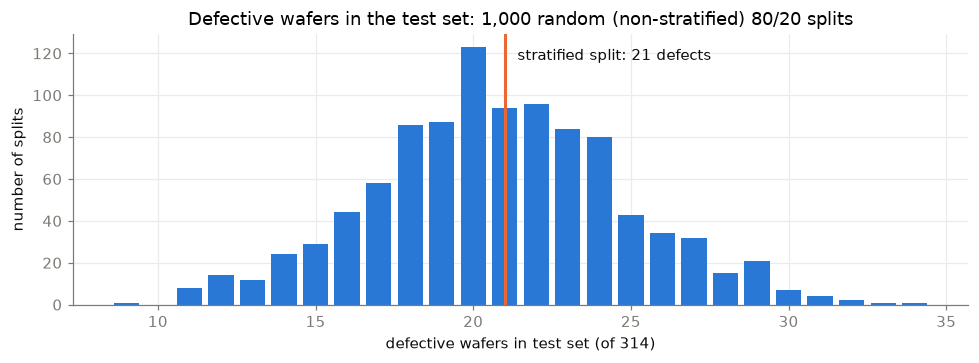

Random splits: 9-34 defects in test (95% of splits between 13 and 29), i.e. a test defect rate of 4.1% to 9.2%.


,dataset,wafers,good (0),defective (1),defective %,share of all wafers %
0,original,1567,1463,104,6.637,100.0
1,train,1253,1170,83,6.624,80.0
2,test,314,293,21,6.688,20.0


test_holdout.csv  sealed, sha256 a5e11d039c4a63be...  (314 rows)
train_raw.csv     sha256 6a563a04d8b234d7...  (1253 rows)
Test set removed from memory. Only X_train / y_train are used from here on.


In [45]:
test_defects = np.array([
    train_test_split(y, test_size=TEST_SIZE, random_state=seed)[1].sum()
    for seed in range(1000)
])
expected = y.sum() * TEST_SIZE

fig, ax = plt.subplots(figsize=(9, 3.4))
values, freq = np.unique(test_defects, return_counts=True)
ax.bar(values, freq, color=BLUE, width=0.8)
ax.axvline(round(expected), color=ORANGE, lw=2)
ax.text(
    round(expected) + 0.4,
    freq.max() * 0.95,
    f"stratified split: {round(expected)} defects",
    color=INK,
)
ax.set(
    title="Defective wafers in the test set: 1,000 random (non-stratified) 80/20 splits",
    xlabel="defective wafers in test set (of 314)",
    ylabel="number of splits",
)
savefig(fig, "02_random_vs_stratified_split.png")

low, high = np.percentile(test_defects, [2.5, 97.5])
print(
    f"Random splits: {test_defects.min()}-{test_defects.max()} defects in test "
    f"(95% of splits between {low:.0f} and {high:.0f}), i.e. a test defect rate of "
    f"{low / 314:.1%} to {high / 314:.1%}."
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)

def describe_split(name: str, target: pd.Series) -> dict:
    return {
        "dataset": name,
        "wafers": len(target),
        "good (0)": int((target == 0).sum()),
        "defective (1)": int(target.sum()),
        "defective %": round(target.mean() * 100, 3),
        "share of all wafers %": round(len(target) / len(y) * 100, 1),
    }

split_table = pd.DataFrame([
    describe_split("original", y),
    describe_split("train", y_train),
    describe_split("test", y_test),
])
display(split_table)

gap_train = abs(y_train.mean() - y.mean()) * 100
gap_test = abs(y_test.mean() - y.mean()) * 100
assert gap_train < 0.1 and gap_test < 0.1, "stratification failed"
assert X_train.index.intersection(X_test.index).empty, "train and test overlap"

test_path = PROCESSED / "test_holdout.csv"
train_raw_path = PROCESSED / "train_raw.csv"
test_hash = save_split(X_test, y_test, test_path, seal=True)
train_hash = save_split(X_train, y_train, train_raw_path, seal=False)
assert verify_sealed(test_path), "test set checksum verification failed"

print(f"test_holdout.csv  sealed, sha256 {test_hash[:16]}...  ({len(X_test)} rows)")
print(f"train_raw.csv     sha256 {train_hash[:16]}...  ({len(X_train)} rows)")

del X_test, y_test, X, y
assert "X_test" not in globals() and "y_test" not in globals()
print("Test set removed from memory. Only X_train / y_train are used from here on.")

log_diary_entry(
    DIARY_PATH,
    "D-001",
    "Stratified 80/20 Train/Test Split & Test Sealing",
    f"Split 80/20 stratified on target (random_state={RANDOM_STATE}) and sealed test_holdout.csv with SHA-256.",
    "Preserves ~6.6% minority defect rate in train and test while preventing any test-set leakage.",
    f"Train: {len(X_train)} rows ({int(y_train.sum())} defects); test holdout sealed and deleted from memory.",
)


columns: 590   variance exactly 0: 116   variance undefined (<2 observed values): 0
smallest non-zero variance: 1.102e-08   (kept, because it is not exactly 0)


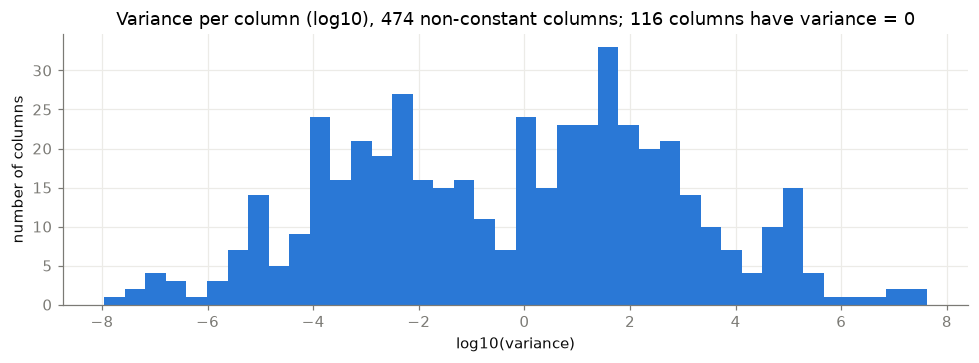

zero-variance columns: 005, 013, 042, 049, 052, 069, 097, 141, 149, 178, 179, 186, 189, 190, 191, 192, 193, 194, 226, 229, 230, 231, 232, 233, 234, 235, 236, 237, 240, 241, 242, 243, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 276, 284, 313, 314, 315, 322, 325, 326, 327, 328, 329, 330, 364, 369, 370, 371, 372, 373, 374, 375, 378, 379, 380, 381, 394, 395, 396, 397, 398, 399, 400, 401, 402, 403, 404, 414, 422, 449, 450, 451, 458, 461, 462, 463, 464, 465, 466, 481, 498, 501, 502, 503, 504, 505, 506, 507, 508, 509, 512, 513, 514, 515, 528, 529, 530, 531, 532, 533, 534, 535, 536, 537, 538
590 -> 474 columns (116 removed)


,Option,Pros & Cons,Decision,Consequence
0,Remove columns with variance exactly 0,+ Zero discriminative power; lossless removal....,CHOSEN,"590 -> 474 columns (116 removed, 19.7%)."
1,Also remove near-constant columns (small varia...,+ Reduces more columns early.\n- Variance depe...,Not chosen,Smallest non-zero variance is 1.10e-08; retain...
2,Keep all columns,+ No risk of dropping any column.\n- Constant ...,Not chosen,-


In [46]:
variance, zero_var_cols = zero_variance_features(X_train)
n_before = X_train.shape[1]
print(
    f"columns: {n_before}   variance exactly 0: {len(zero_var_cols)}   "
    f"variance undefined (<2 observed values): {int(variance.isna().sum())}"
)
nonzero = variance[variance > 0]
print(f"smallest non-zero variance: {nonzero.min():.3e}   (kept, because it is not exactly 0)")

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist(np.log10(nonzero), bins=40, color=BLUE)
ax.set(
    title=f"Variance per column (log10), {len(nonzero)} non-constant columns; "
          f"{len(zero_var_cols)} columns have variance = 0",
    xlabel="log10(variance)",
    ylabel="number of columns",
)
savefig(fig, "03_variance_per_column.png")
print("zero-variance columns:", ", ".join(c.replace("feature_", "") for c in zero_var_cols))

X_train_1 = X_train.drop(columns=zero_var_cols)
n_after_constant = X_train_1.shape[1]
print(f"{n_before} -> {n_after_constant} columns ({len(zero_var_cols)} removed)")

display(sip_table([
    (
        "Remove columns with variance exactly 0",
        "+ Zero discriminative power; lossless removal.\n"
        "+ Objective rule with no arbitrary cut-off.\n- None for constant signals.",
        "CHOSEN",
        f"{n_before} -> {n_after_constant} columns ({len(zero_var_cols)} removed, "
        f"{len(zero_var_cols) / n_before:.1%}).",
    ),
    (
        "Also remove near-constant columns (small variance cut-off)",
        "+ Reduces more columns early.\n- Variance depends on measurement units/scale; "
        "rare excursions can be informative.",
        "Not chosen",
        f"Smallest non-zero variance is {nonzero.min():.2e}; retained for feature selection.",
    ),
    (
        "Keep all columns",
        "+ No risk of dropping any column.\n- Constant columns add noise and overhead.",
        "Not chosen",
        "-",
    ),
]))

log_diary_entry(
    DIARY_PATH,
    "D-002",
    "Remove Zero-Variance Columns (Training Set Only)",
    f"Dropped {len(zero_var_cols)} columns with exact variance == 0 on X_train.",
    "Constant columns cannot separate pass from fail wafers.",
    f"Columns reduced from {n_before} to {n_after_constant}.",
)


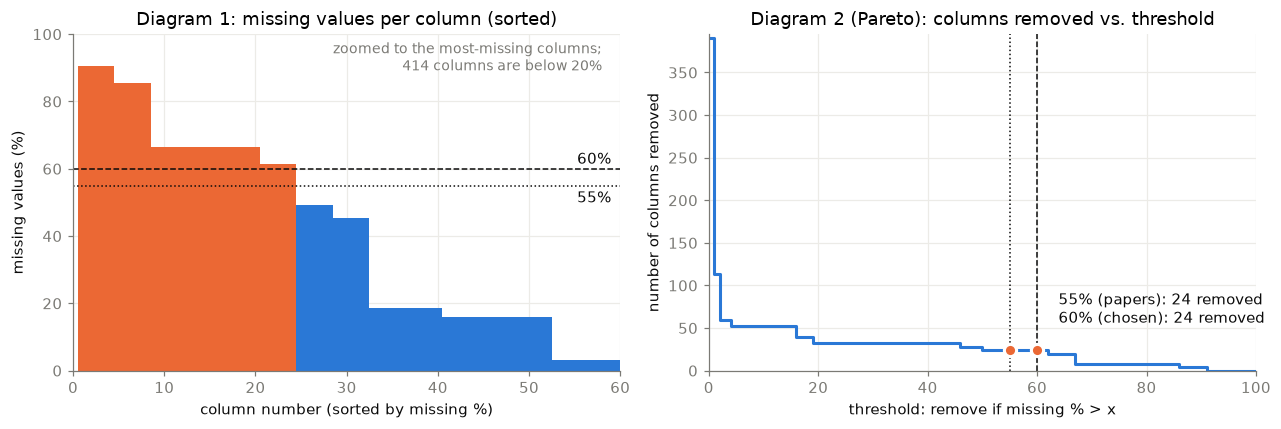

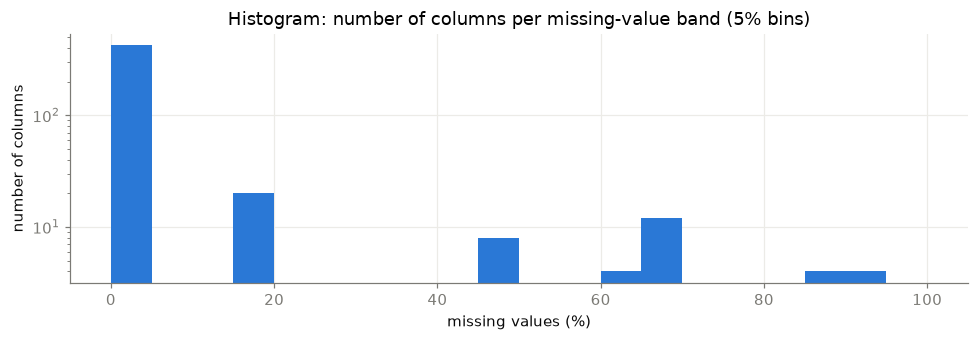

missing %,45.3,49.1,61.3,66.3,85.6,90.7
columns,4,4,4,12,4,4


threshold_pct,20,40,45,50,55,60,65,70,80,90
columns_removed,32,32,32,24,24,24,20,8,8,4


474 -> 450 columns (24 removed)
missing cells: 33,091 -> 11,211 (5.57% -> 1.99% of cells)
removed: 085, 109, 110, 111, 157, 158, 220, 244, 245, 246, 292, 293, 358, 382, 383, 384, 492, 516, 517, 518, 578, 579, 580, 581


,Option,Pros & Cons,Decision,Consequence
0,Threshold 55% (as in the papers),+ Matches published SECOM preprocessing.\n- Id...,Not chosen (same result),would remove 24 columns
1,Threshold 60% (chosen cut-off),+ Sits cleanly in the plateau gap; avoids over...,CHOSEN,474 -> 450 columns (24 removed); missing cells...
2,Lower threshold (e.g. 40-45%),+ Less imputation burden.\n- Drops moderate-mi...,Not chosen,would remove 32 columns
3,Higher threshold (e.g. 70-80%) or keep all,+ Keeps all signals.\n- Imputer must synthesiz...,Not chosen,70%: would remove 8 columns
4,Drop rows with missing values,- Deletes every wafer because no row is complete.,Not chosen,-


In [47]:
missing_pct = missing_percentage(X_train_1)
pareto = missing_threshold_pareto(missing_pct)
PAPER_THRESHOLD, THRESHOLD = 55, 60

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ordered = missing_pct.sort_values(ascending=False).reset_index(drop=True)
removed_mask = ordered > THRESHOLD
axes[0].bar(
    ordered.index + 1,
    ordered,
    width=1.0,
    color=np.where(removed_mask, ORANGE, BLUE),
)
for t, style in ((PAPER_THRESHOLD, ":"), (THRESHOLD, "--")):
    axes[0].axhline(t, color=INK, ls=style, lw=1)
    axes[0].text(59, t + (1.5 if t == THRESHOLD else -5), f"{t}%", ha="right", color=INK)
axes[0].set(
    title="Diagram 1: missing values per column (sorted)",
    xlabel="column number (sorted by missing %)",
    ylabel="missing values (%)",
    ylim=(0, 100),
)
axes[0].set_xlim(0, min(60, len(ordered)))
axes[0].text(
    min(58, len(ordered) - 1),
    98,
    f"zoomed to the most-missing columns;\n{max(0, len(ordered) - 60)} columns are below 20%",
    ha="right",
    va="top",
    color=MUTED,
    fontsize=9,
)

axes[1].step(pareto["threshold_pct"], pareto["columns_removed"], where="post", color=BLUE, lw=2)
n_at = {
    t: int(pareto.loc[pareto["threshold_pct"] == t, "columns_removed"].iloc[0])
    for t in (PAPER_THRESHOLD, THRESHOLD)
}
for t, style in ((PAPER_THRESHOLD, ":"), (THRESHOLD, "--")):
    axes[1].axvline(t, color=INK, ls=style, lw=1)
    axes[1].plot(t, n_at[t], "o", color=ORANGE, ms=8, mec="white", mew=2, zorder=3)
axes[1].annotate(
    f"55% (papers): {n_at[PAPER_THRESHOLD]} removed\n60% (chosen): {n_at[THRESHOLD]} removed",
    (THRESHOLD, n_at[THRESHOLD]),
    xytext=(14, 18),
    textcoords="offset points",
    color=INK,
)
axes[1].set(
    title="Diagram 2 (Pareto): columns removed vs. threshold",
    xlabel="threshold: remove if missing % > x",
    ylabel="number of columns removed",
    xlim=(0, 100),
)
axes[1].set_ylim(0, max(70, int(pareto["columns_removed"].max()) + 5))
savefig(fig, "04_missing_values_threshold.png")

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(missing_pct, bins=np.arange(0, 105, 5), color=BLUE)
ax.set(
    title="Histogram: number of columns per missing-value band (5% bins)",
    xlabel="missing values (%)",
    ylabel="number of columns",
)
ax.set_yscale("log")
savefig(fig, "05_missing_values_histogram.png")

levels = (
    missing_pct[missing_pct > 20]
    .round(1)
    .value_counts()
    .sort_index()
    .rename_axis("missing %")
    .rename("columns")
    .to_frame()
)
display(levels.T)

candidate = pareto[pareto["threshold_pct"].isin([20, 40, 45, 50, 55, 60, 65, 70, 80, 90])]
display(candidate.set_index("threshold_pct").T)

high_missing_cols = missing_pct.index[missing_pct > THRESHOLD].tolist()
X_train_2 = X_train_1.drop(columns=high_missing_cols)
n_after_missing = X_train_2.shape[1]
cells_before = int(X_train_1.isna().sum().sum())
cells_after = int(X_train_2.isna().sum().sum())

print(f"{n_after_constant} -> {n_after_missing} columns ({len(high_missing_cols)} removed)")
print(
    f"missing cells: {cells_before:,} -> {cells_after:,} "
    f"({X_train_1.isna().mean().mean():.2%} -> {X_train_2.isna().mean().mean():.2%} of cells)"
)
print("removed:", ", ".join(c.replace("feature_", "") for c in high_missing_cols))

removed_at = lambda t: int(pareto.loc[pareto["threshold_pct"] == t, "columns_removed"].iloc[0])
display(sip_table([
    (
        "Threshold 55% (as in the papers)",
        "+ Matches published SECOM preprocessing.\n- Identical removal count to 60% here.",
        "Not chosen (same result)",
        f"would remove {removed_at(55)} columns",
    ),
    (
        "Threshold 60% (chosen cut-off)",
        "+ Sits cleanly in the plateau gap; avoids over-imputing sparse sensors.\n"
        "- Remaining columns up to ~50-60% missing still require imputation.",
        "CHOSEN",
        f"{n_after_constant} -> {n_after_missing} columns ({len(high_missing_cols)} removed); "
        f"missing cells {cells_before:,} -> {cells_after:,}. Cumulative: {n_before} -> "
        f"{n_after_missing} ({n_before - n_after_missing} removed).",
    ),
    (
        "Lower threshold (e.g. 40-45%)",
        "+ Less imputation burden.\n- Drops moderate-missingness groups earlier.",
        "Not chosen",
        f"would remove {removed_at(40)} columns",
    ),
    (
        "Higher threshold (e.g. 70-80%) or keep all",
        "+ Keeps all signals.\n- Imputer must synthesize most values in sparse columns.",
        "Not chosen",
        f"70%: would remove {removed_at(70)} columns",
    ),
    (
        "Drop rows with missing values",
        "- Deletes every wafer because no row is complete.",
        "Not chosen",
        "-",
    ),
]))

log_diary_entry(
    DIARY_PATH,
    "D-003",
    "Drop High-Missingness Columns (> 60% on Training Set)",
    f"Removed {len(high_missing_cols)} columns with > {THRESHOLD}% missing values on X_train_1.",
    "Avoids relying heavily on imputed values in heavily sparse sensors while staying consistent with literature thresholds.",
    f"Columns reduced from {n_after_constant} to {n_after_missing}; missing cells dropped from {cells_before:,} to {cells_after:,}.",
)


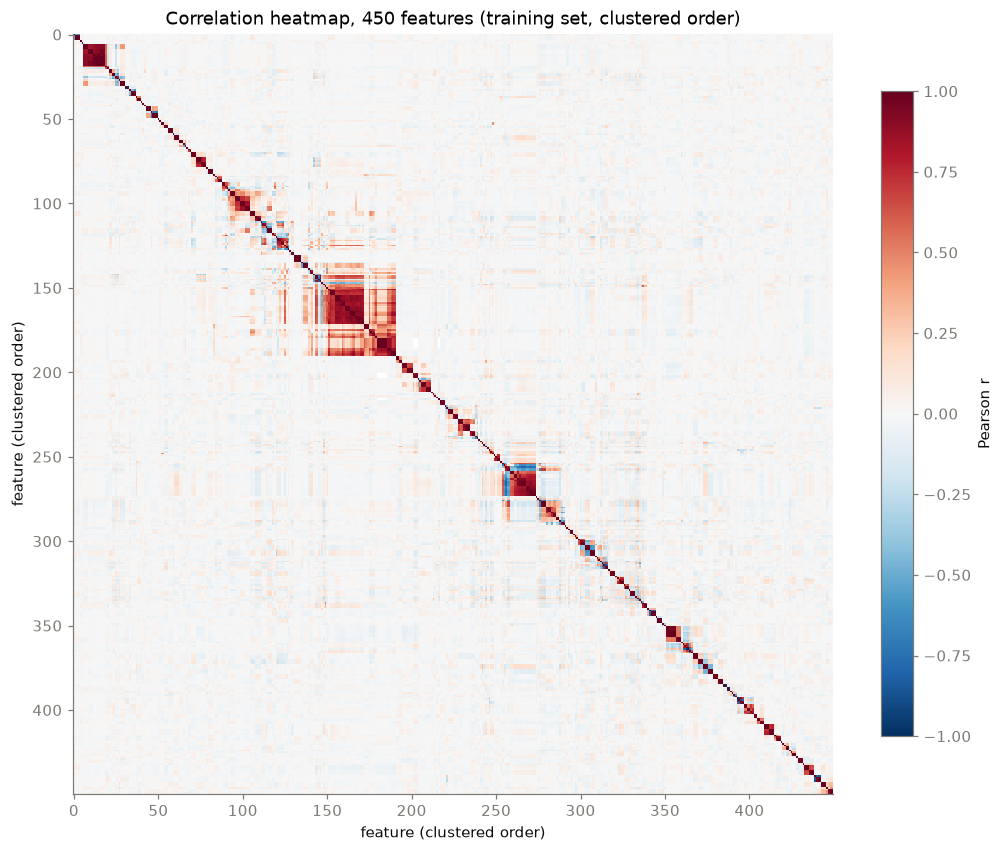

,value
feature pairs,101001
pairs with |r| > 0.8,608
pairs with |r| > 0.9,371
pairs with |r| > 0.9999 (practically identical),26
features involved in at least one |r| > 0.8 pair,335
median |r| over all pairs,0.024


,Option,Pros & Cons,Decision,Consequence
0,Drop one feature per pair with |r| > 0.8 now,+ Quickly trims correlated pairs.\n- Arbitrary...,Not chosen (now),would affect 335 of 450 features
1,Visualise only; defer selection to downstream ...,+ Preserves signal choice for statistical/mode...,CHOSEN,0 columns removed (450 retained); 608 pairs wi...
2,Replace features with PCA components now,+ Compresses correlated blocks.\n- Loses direc...,Not chosen,-


In [48]:
corr = X_train_2.corr()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().dropna()
filled = corr.fillna(0).to_numpy(copy=True)
np.fill_diagonal(filled, 1.0)
distance = np.clip(1 - np.abs(filled), 0, None)
order = leaves_list(linkage(squareform(distance, checks=False), method="average"))
ordered_corr = corr.iloc[order, order]

fig, ax = plt.subplots(figsize=(9.5, 8))
image = ax.imshow(ordered_corr, cmap="RdBu_r", vmin=-1, vmax=1, interpolation="nearest")
ax.set(
    title=f"Correlation heatmap, {corr.shape[0]} features (training set, clustered order)",
    xlabel="feature (clustered order)",
    ylabel="feature (clustered order)",
)
ax.grid(False)
fig.colorbar(image, ax=ax, shrink=0.8, label="Pearson r")
savefig(fig, "06_correlation_heatmap.png")

strong = upper[upper.abs() > 0.8]
involved = set(strong.index.get_level_values(0)) | set(strong.index.get_level_values(1))
summary = pd.Series({
    "feature pairs": len(upper),
    "pairs with |r| > 0.8": len(strong),
    "pairs with |r| > 0.9": int((upper.abs() > 0.9).sum()),
    "pairs with |r| > 0.9999 (practically identical)": int((upper.abs() > 0.9999).sum()),
    "features involved in at least one |r| > 0.8 pair": len(involved),
    "median |r| over all pairs": round(float(upper.abs().median()), 3),
}, name="value", dtype=object)
display(summary.to_frame())

display(sip_table([
    (
        "Drop one feature per pair with |r| > 0.8 now",
        "+ Quickly trims correlated pairs.\n- Arbitrary choice of which correlated feature to drop.",
        "Not chosen (now)",
        f"would affect {len(involved)} of {corr.shape[0]} features",
    ),
    (
        "Visualise only; defer selection to downstream feature selection",
        "+ Preserves signal choice for statistical/model-based selection.\n"
        "- Retains collinear columns through early preparation.",
        "CHOSEN",
        f"0 columns removed ({corr.shape[0]} retained); {len(strong)} pairs with |r| > 0.8 documented.",
    ),
    (
        "Replace features with PCA components now",
        "+ Compresses correlated blocks.\n- Loses direct sensor interpretability.",
        "Not chosen",
        "-",
    ),
]))

log_diary_entry(
    DIARY_PATH,
    "D-004",
    "Correlation Audit Only (No Pairwise Pruning)",
    f"Computed pairwise Pearson correlation on {corr.shape[0]} training features without dropping columns.",
    "Avoids arbitrary feature dropping before supervised feature selection.",
    f"Retained all {corr.shape[0]} features; identified {len(strong)} pairs with |r| > 0.8.",
)


,value
observed values,552639
outlier values (3σ),4872
outlier share of observed values %,0.882
columns with at least one outlier,412
max outliers in one column,61
wafers with at least one outlier,1008
wafers with at least one outlier %,80.4


,wafers,defect_rate
1 outliers,449,4.90
2 outliers,187,5.88
3-5 outliers,323,7.74
6-52 outliers,294,8.50


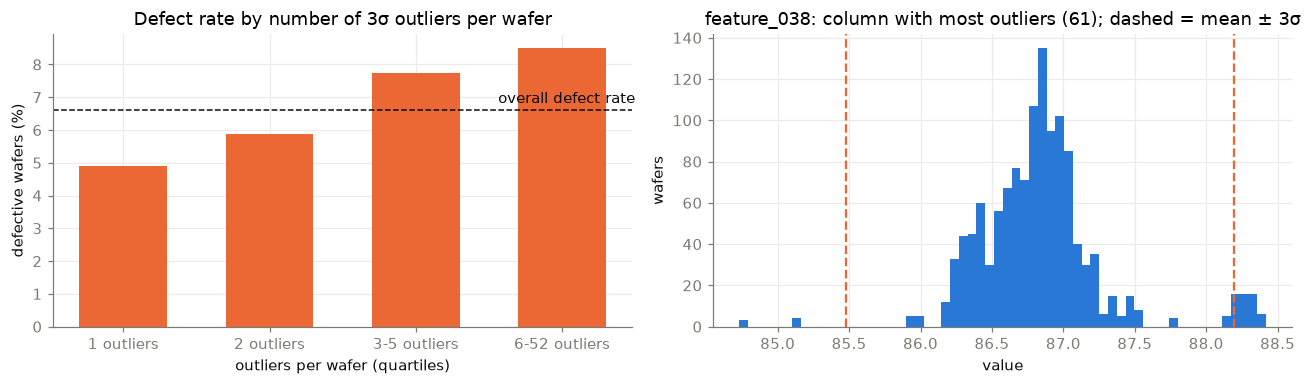

,values changed,new NaNs introduced,mean cols with |std change| > 5%
do nothing,0,0,0
cap at mean ± 3σ,4872,0,285
set to NaN,4872,4872,342


,Option,Pros & Cons,Decision,Consequence
0,Do nothing (keep raw extreme values),+ Preserves extreme sensor excursions.\n- Extr...,Not chosen,"0 of 4,872 3σ outlier cells modified."
1,Cap at mean ± 3σ (winsorise on training set),+ Bounds extreme spikes without losing rows or...,CHOSEN,"Capped 4,872 3σ cells on X_train; 450 features..."
2,Remove outliers to NaN,+ Prevents extreme values from biasing fits.\n...,Not chosen,"would add 4,872 new NaN cells."


In [49]:
bounds = three_sigma_bounds(X_train_2, k=3.0)
is_outlier = flag_outliers(X_train_2, bounds)
observed = int(X_train_2.notna().sum().sum())
outlier_cells = int(is_outlier.sum().sum())
per_col = is_outlier.sum()
per_row = is_outlier.sum(axis=1)

outlier_overview = pd.Series({
    "observed values": observed,
    "outlier values (3σ)": outlier_cells,
    "outlier share of observed values %": round(outlier_cells / observed * 100, 3),
    "columns with at least one outlier": int(per_col.gt(0).sum()),
    "max outliers in one column": int(per_col.max()),
    "wafers with at least one outlier": int(per_row.gt(0).sum()),
    "wafers with at least one outlier %": round(per_row.gt(0).mean() * 100, 1),
}, name="value", dtype=object)
display(outlier_overview.to_frame())

quartile = pd.qcut(per_row, 4, duplicates="drop")
signal = y_train.groupby(quartile, observed=True).agg(wafers="size", defect_rate="mean")
signal["defect_rate"] = (signal["defect_rate"] * 100).round(2)


def _label(interval) -> str:
    low, high = max(int(interval.left) + 1, 0), int(interval.right)
    return f"{low} outliers" if low == high else f"{low}-{high} outliers"


signal.index = [_label(i) for i in signal.index]
display(signal)

example = per_col.idxmax()
values = X_train_2[example].dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].bar(signal.index, signal["defect_rate"], color=ORANGE, width=0.6)
axes[0].axhline(y_train.mean() * 100, color=INK, ls="--", lw=1)
axes[0].text(
    len(signal) - 0.5,
    y_train.mean() * 100 + 0.2,
    "overall defect rate",
    ha="right",
    color=INK,
)
axes[0].set(
    title="Defect rate by number of 3σ outliers per wafer",
    ylabel="defective wafers (%)",
    xlabel="outliers per wafer (quartiles)",
)
axes[1].hist(values, bins=60, color=BLUE)
for edge in ("lower", "upper"):
    axes[1].axvline(bounds.loc[example, edge], color=ORANGE, ls="--", lw=1.5)
axes[1].set(
    title=f"{example}: column with most outliers ({int(per_col.max())}); dashed = mean ± 3σ",
    xlabel="value",
    ylabel="wafers",
)
savefig(fig, "07_outliers_3sigma.png")

X_cap = cap_outliers(X_train_2, bounds)
X_gap = remove_outliers(X_train_2, bounds)
std_before = X_train_2.std()

compare = pd.DataFrame({
    "values changed": [0, outlier_cells, outlier_cells],
    "new NaNs introduced": [0, 0, outlier_cells],
    "mean cols with |std change| > 5%": [
        0,
        int(((X_cap.std() - std_before).abs() / std_before.replace(0, np.nan) > 0.05).sum()),
        int(((X_gap.std() - std_before).abs() / std_before.replace(0, np.nan) > 0.05).sum()),
    ],
}, index=["do nothing", "cap at mean ± 3σ", "set to NaN"])
display(compare)

# Chosen option: cap outliers at mean ± 3σ on the training set (X_train_3)
X_train_3 = X_cap
display(sip_table([
    (
        "Do nothing (keep raw extreme values)",
        "+ Preserves extreme sensor excursions.\n- Extreme values distort scales and distance/linear models.",
        "Not chosen",
        f"0 of {outlier_cells:,} 3σ outlier cells modified.",
    ),
    (
        "Cap at mean ± 3σ (winsorise on training set)",
        "+ Bounds extreme spikes without losing rows or adding missingness.\n"
        "- Clips tail values in skewed sensors.",
        "CHOSEN",
        f"Capped {outlier_cells:,} 3σ cells on X_train; {X_train_3.shape[1]} features retained.",
    ),
    (
        "Remove outliers to NaN",
        f"+ Prevents extreme values from biasing fits.\n- Adds {outlier_cells:,} missing cells for imputation.",
        "Not chosen",
        f"would add {outlier_cells:,} new NaN cells.",
    ),
]))

log_diary_entry(
    DIARY_PATH,
    "D-005",
    "Outlier Treatment via 3σ Capping (Training Set Only)",
    f"Computed mean ± 3σ bounds on X_train_2 and capped {outlier_cells:,} extreme cells.",
    "Controls extreme scale distortion while keeping sample count intact and avoiding extra missingness.",
    f"Prepared X_train_3 with {X_train_3.shape[0]} rows and {X_train_3.shape[1]} columns.",
)


In [50]:
train_prep_path = PROCESSED / "train_prepared_step2.csv"
state_path = PROCESSED / "prep_step1_2_state.json"

train_prep_hash = save_split(X_train_3, y_train, train_prep_path, seal=False)

funnel = pd.DataFrame([
    {"stage": "0. Raw SECOM", "rows": len(X_train), "columns": n_before, "missing_cells": int(X_train.isna().sum().sum())},
    {"stage": "1. After zero-variance drop", "rows": len(X_train_1), "columns": n_after_constant, "missing_cells": int(X_train_1.isna().sum().sum())},
    {"stage": "2. After >60% missing drop", "rows": len(X_train_2), "columns": n_after_missing, "missing_cells": int(X_train_2.isna().sum().sum())},
    {"stage": "3. After 3σ capping (saved)", "rows": len(X_train_3), "columns": X_train_3.shape[1], "missing_cells": int(X_train_3.isna().sum().sum())},
])
display(funnel)

state = {
    "random_state": RANDOM_STATE,
    "test_size": TEST_SIZE,
    "missing_threshold_pct": THRESHOLD,
    "outlier_k_sigma": 3.0,
    "zero_variance_removed": zero_var_cols,
    "high_missing_removed": high_missing_cols,
    "final_train_rows": int(X_train_3.shape[0]),
    "final_train_cols": int(X_train_3.shape[1]),
    "test_holdout_sha256": test_hash,
    "train_prepared_sha256": train_prep_hash,
}
save_state(state, state_path)
print("Saved prepared training set:", train_prep_path)
print("Saved state metadata:", state_path)
print("Updated diary:", DIARY_PATH)


,stage,rows,columns,missing_cells
0,0. Raw SECOM,1253,590,33868
1,1. After zero-variance drop,1253,474,33091
2,2. After >60% missing drop,1253,450,11211
3,3. After 3σ capping (saved),1253,450,11211


Saved prepared training set: C:\Users\LindaAlyAbdellateefA\Downloads\SECOM\secom\data\processed\train_prepared_step2.csv
Saved state metadata: C:\Users\LindaAlyAbdellateefA\Downloads\SECOM\secom\data\processed\prep_step1_2_state.json
Updated diary: C:\Users\LindaAlyAbdellateefA\Downloads\SECOM\secom\docs\scientific_diary.md
